# Final Project: Analyzing Historical Stock/Revenue Data and Building a Dashboard

This notebook follows the six upload questions on the assignment page. Run all cells in Google Colab with internet access, check that each cell succeeds, and save the executed notebook with outputs.

**Note:** The assignment asks for screenshots from your executed notebook. The notebook itself is not a substitute for the six screenshots.


## Question 1 — Use yfinance to Extract Tesla Stock Data

In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

tesla = yf.Ticker("TSLA")
tesla_data = tesla.history(period="max")
tesla_data.reset_index(inplace=True)

# Display the first five rows
tesla_data.head()


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## Question 2 — Use Webscraping to Extract Tesla Revenue Data

In [ ]:
import pandas as pd
import requests

tesla_url = "https://en.wikipedia.org/wiki/Tesla,_Inc."
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"}

response = requests.get(tesla_url, headers=headers)
tesla_tables = pd.read_html(response.text)

# Find a table containing revenue data
tesla_revenue = None
for table in tesla_tables:
    cols = [str(col).lower() for col in table.columns]
    if any("revenue" in col for col in cols):
        tesla_revenue = table.copy()
        break

if tesla_revenue is None:
    raise ValueError("Revenue table not found. Inspect tesla_tables and select the correct table.")

# Clean currency symbols and citation markers where present
tesla_revenue = tesla_revenue.replace(r"\$", "", regex=True)
tesla_revenue = tesla_revenue.replace(",", "", regex=True)
tesla_revenue = tesla_revenue.replace(r"\[\d+\]", "", regex=True)
display(tesla_revenue.tail())

/tmp/ipykernel_4143/3934890734.py:8: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tesla_tables = pd.read_html(response.text)


,Year,Revenue (US$ m),Net income (US$ m),Total assets (US$ m),Employees,Ref.
16,2021,53823,5519,62131,99290.0,
17,2022,81462,12556,82338,127855.0,
18,2023,96773,14997,106618,140473.0,
19,2024,97690,7091,122070,125665.0,
20,2025,94827,3794,137806,134785.0,


## Question 3 — Use yfinance to Extract GameStop Stock Data

In [ ]:
gme = yf.Ticker("GME")
gme_data = gme.history(period="max")
gme_data.reset_index(inplace=True)

# Display the first five rows
gme_data.head()


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620128,1.693350,1.603296,1.691666,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683251,1.687459,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


## Question 4 — Use Webscraping to Extract GameStop Revenue Data

In [ ]:
import pandas as pd
import requests
from io import StringIO

gme_url = "https://en.wikipedia.org/wiki/GameStop"
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"}

response = requests.get(gme_url, headers=headers)
gme_tables = pd.read_html(StringIO(response.text))

# Find the table containing regional financial data (e.g., Australia, Canada, United States, etc.)
gme_revenue = None
for table in gme_tables:
    if isinstance(table.columns, pd.MultiIndex):
        cols_joined = " ".join([str(col).lower() for col in table.columns.to_flat_index()])
        if "australia" in cols_joined or "united states" in cols_joined or "revenue" in cols_joined:
            gme_revenue = table.copy()
            break

if gme_revenue is None:
    # Fallback to the previous logic if not found
    for table in gme_tables:
        if len(table) > 0 and len(table.columns) > 1:
            first_col_series = table.iloc[:, 0].astype(str).str.lower()
            if first_col_series.str.contains("revenue").any():
                gme_revenue = table.copy()
                break

# Clean currency symbols and citation markers where present
gme_revenue = gme_revenue.replace(r"\$", "", regex=True)
gme_revenue = gme_revenue.replace(",", "", regex=True)
gme_revenue = gme_revenue.replace(r"\[\d+\]", "", regex=True)
display(gme_revenue.tail())

Unnamed: 0_level_0                Australia                           \
                       Year                Net sales         Operating income   
23                     2022                    588.7                     13.8   
24                     2023                    522.5                     -3.5   
25                     2024                    404.9                    -11.9   
26                     2025                    494.7                      4.6   
27  Amounts in millions USD  Amounts in millions USD  Amounts in millions USD   

                     Canada                                            Europe  \
                  Net sales         Operating income                Net sales   
23                    344.1                     -8.6                    901.4   
24                    292.5                     -8.4                   1028.4   
25                    204.3                    -10.0                    638.1   
26                     38.2                    -22.2                    429.4   
27  Amounts in millions USD  Amounts in millions USD  Amounts in millions USD   

                                       United States                           \
           Operating income                Net sales         Operating income   
23                    -30.6                   4093.0                   -286.2   
24                    -20.2                   3429.4                     -2.4   
25                    -38.2                   2757.7                     33.9   
26                    -33.5                   2667.6                    283.2   
27  Amounts in millions USD  Amounts in millions USD  Amounts in millions USD   

          Technology brands                                             Total  \
                  Net sales         Operating income                Net sales   
23                        -                        -                   5927.2   
24                        -                        -                   5272.8   
25                        -                        -                   3823.0   
26                        -                        -                   3629.9   
27  Amounts in millions USD  Amounts in millions USD  Amounts in millions USD   

                             
           Operating income  
23                   -311.6  
24                    -34.5  
25                    -26.2  
26                    232.1  
27  Amounts in millions USD

## Shared plotting function for Questions 5 and 6

In [ ]:
def make_graph(stock_data, title):
    data = stock_data.copy()
    date_col = "Date" if "Date" in data.columns else data.columns[0]
    data[date_col] = pd.to_datetime(data[date_col], errors="coerce")
    data["Close"] = pd.to_numeric(data["Close"], errors="coerce")
    data = data.dropna(subset=[date_col, "Close"]).sort_values(date_col)

    plt.figure(figsize=(12, 5))
    plt.plot(data[date_col], data["Close"])
    plt.title(title)
    plt.xlabel("Date")
    plt.ylabel("Share Price (US$)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## Question 5 — Plot Tesla Stock Graph

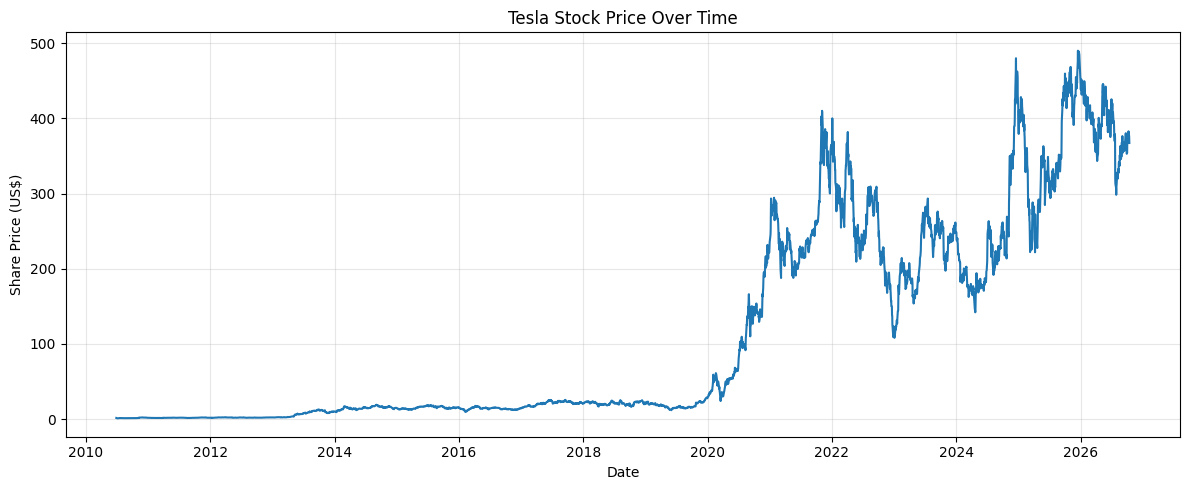

In [ ]:
make_graph(tesla_data, "Tesla Stock Price Over Time")


## Question 6 — Plot GameStop Stock Graph

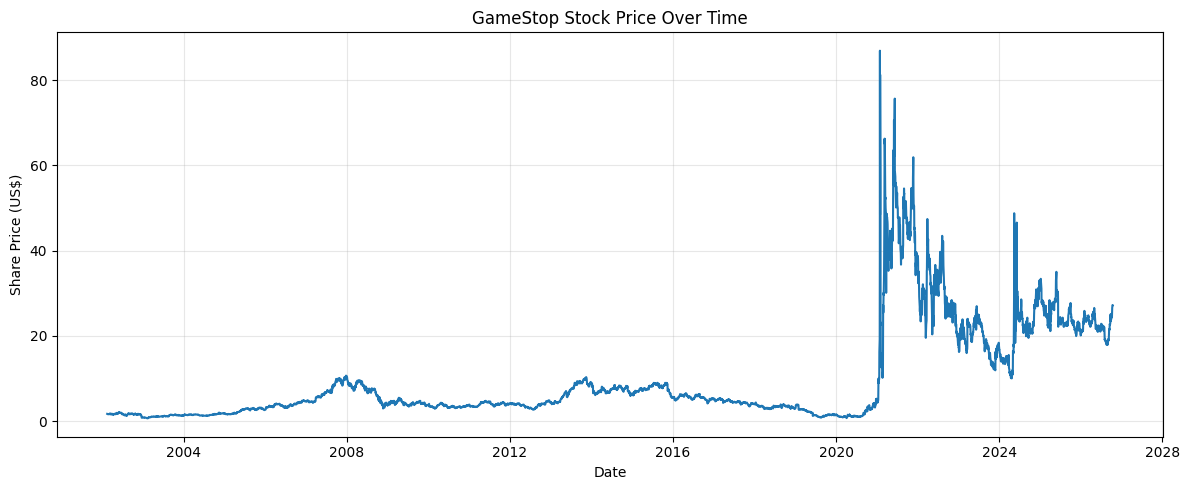

In [ ]:
make_graph(gme_data, "GameStop Stock Price Over Time")
